# Moving a repo across an air gap with QR sheets

This notebook runs the whole pipeline end to end on a throwaway sample repo, so you
can watch each stage before pointing it at anything real. Nothing here touches
`kretsinger/` — all work happens in a temp directory that the last cell tells you how
to delete.

**The scenario.** A machine with no network, no USB, no git. The only channel out is
its screen. We compress the repo, encode it as QR codes, lay them out as sheets sized
for that machine's display, photograph the sheets, and rebuild the tree byte-for-byte
on the receiving machine.

**Roles of the three scripts:**

| script | runs on | why |
|---|---|---|
| `agmini.py` | offline machine | 67 lines — short enough to type by hand, which is the only way to get code onto a machine that can't receive files |
| `agpack.py` | offline machine | full version: resolution-aware layout, secret filtering, manifests, calibration |
| `agunpack.py` | this machine | decodes photos, verifies, rebuilds |

To keep this notebook self-contained it fakes the camera with PIL rather than driving a
real browser, so no headless-Chrome dependency. The degradation model is the same one
used to validate the tools: perspective tilt, rotation, blur, glare, sensor noise, JPEG.

## 0. Dependencies

In [ ]:
import importlib, sys

REQUIRED = {
    "segno": "pip install segno                 # QR encoding (offline machine)",
    "PIL": "pip install pillow                # imaging",
    "pyzbar": "pip install pyzbar                # QR decoding (this machine)\n"
    "                                    ...plus the C library: brew install zbar",
}
missing = []
for mod, how in REQUIRED.items():
    try:
        importlib.import_module(mod)
        print(f"  ok       {mod}")
    except Exception:
        print(f"  MISSING  {mod:8} ->  {how}")
        missing.append(mod)

print()
print(
    "All present - run the rest of the notebook."
    if not missing
    else "Install the missing packages above, then restart the kernel."
)
print(f"python: {sys.executable}")

  MISSING  segno    ->  pip install segno                 # QR encoding (offline machine)
  ok       PIL
  MISSING  pyzbar   ->  pip install pyzbar                # QR decoding (this machine)
                                    ...plus the C library: brew install zbar

Install the missing packages above, then restart the kernel.
python: /Users/Akseldkw/micromamba/envs/kret_312/bin/python


## 1. A sample repo to send

A few hand-written modules, plus a `vendor/` directory filled with real modules copied
out of your own Python standard library. That last part matters: made-up filler
compresses unrealistically well, and the whole estimate depends on the compression
ratio of *actual* source code. Borrowing stdlib files gives an honest number and works
on any machine.

The `.env` file exists specifically to show that it gets left behind.

In [ ]:
import os, pathlib, tempfile, textwrap

WORK = pathlib.Path(tempfile.mkdtemp(prefix="agdemo-"))
SRC = WORK / "sample-repo"
(SRC / "pkg").mkdir(parents=True)
(SRC / "docs").mkdir()

(SRC / "pkg" / "__init__.py").write_text('__version__ = "0.3.1"\n')
(SRC / "pkg" / "solver.py").write_text(textwrap.dedent("""
    # A module whose indentation had better survive the trip.

    def bisect(f, lo, hi, tol=1e-12, max_iter=200):
        flo = f(lo)
        if flo * f(hi) > 0:
            raise ValueError("f(lo) and f(hi) must straddle a root")
        for _ in range(max_iter):
            mid = (lo + hi) / 2
            fmid = f(mid)
            if abs(fmid) < tol or (hi - lo) / 2 < tol:
                return mid
            if flo * fmid < 0:
                hi = mid
            else:
                lo, flo = mid, fmid
        return (lo + hi) / 2
""").lstrip())
(SRC / "pkg" / "io_utils.py").write_text(textwrap.dedent("""
    import json, pathlib

    def load_config(path):
        p = pathlib.Path(path)
        if not p.exists():
            return {"mode": "default", "retries": 3}
        return json.loads(p.read_text())
""").lstrip())
(SRC / "docs" / "README.md").write_text("# sample-repo\n\nDemonstration payload for the QR transfer toolkit.\n")
(SRC / "pyproject.toml").write_text('[project]\nname = "sample-repo"\nversion = "0.3.1"\n')
(SRC / "run.sh").write_text("#!/bin/sh\npython3 -m pkg\n")
os.chmod(SRC / "run.sh", 0o755)

# Deliberately present, deliberately not transferred:
(SRC / ".env").write_text("API_TOKEN=sk-do-not-photograph-me\n")

# Bulk it out with genuine source code so the compression ratio is realistic.
import shutil, sysconfig

stdlib = pathlib.Path(sysconfig.get_paths()["stdlib"])
(SRC / "vendor").mkdir(exist_ok=True)
budget, copied = 160_000, 0
for p in sorted(stdlib.glob("*.py")):
    try:
        size = p.stat().st_size
    except OSError:
        continue
    if not (3_000 < size < 40_000) or copied + size > budget:
        continue
    shutil.copy(p, SRC / "vendor" / p.name)
    copied += size

files = sorted(q for q in SRC.rglob("*") if q.is_file())
for p in files[:8]:
    print(f"  {p.stat().st_size:>7} B  {p.relative_to(SRC)}")
print(f"  ... and {len(files) - 8} more (vendor/)")
print(f"\n{len(files)} files, {sum(p.stat().st_size for p in files):,} bytes")
print(f"sample repo at: {SRC}")

       34 B  .env
       66 B  docs/README.md
       22 B  pkg/__init__.py
      181 B  pkg/io_utils.py
      485 B  pkg/solver.py
       49 B  pyproject.toml
       25 B  run.sh
     5218 B  vendor/__future__.py
  ... and 13 more (vendor/)

21 files, 158,344 bytes
sample repo at: /var/folders/dj/k5kk5wk90vvcnb_wphpw490r0000gn/T/agdemo-_zp_khjn/sample-repo


## 2. Estimate before you commit

`--estimate` writes nothing. It reports the compressed size and how many photos each
density level would cost, so you can tune `--ext` until the number is one you're
willing to shoot.

The three levels differ only in **pixels per QR module on the sending screen** — the
number that decides whether a transfer is physically possible. A symbol drawn at
2 px/module holds no recoverable detail regardless of how good the camera is.

In [ ]:
import subprocess, sys


def clean(text):
    """Drop the \r progress lines and collapse the blank runs they leave."""
    out, blank = [], False
    for line in text.splitlines():
        if line.startswith("  pass "):
            continue
        if not line.strip():
            if blank:
                continue
            blank = True
        else:
            blank = False
        out.append(line)
    return "\n".join(out).strip()


def run(*args, show=True):
    r = subprocess.run([sys.executable, *map(str, args)], capture_output=True, text=True)
    if show:
        print(clean(r.stdout))
        if r.stderr.strip():
            print("STDERR:", r.stderr, file=sys.stderr)
    return r


run("agpack.py", "--root", SRC, "--ext", ".py,.md,.toml,.sh", "--screen", "1920x1080", "--estimate")

STDERR: No QR backend available. Tried:
  segno: No module named 'segno'
  qrcode: No module named 'qrcode'
  qrencode(cli): qrencode not on PATH

Install one of:  pip install segno   |   pip install qrcode
                 apt install qrencode | brew install qrencode



CompletedProcess(args=['/Users/Akseldkw/micromamba/envs/kret_312/bin/python', 'agpack.py', '--root', '/var/folders/dj/k5kk5wk90vvcnb_wphpw490r0000gn/T/agdemo-_zp_khjn/sample-repo', '--ext', '.py,.md,.toml,.sh', '--screen', '1920x1080', '--estimate'], returncode=1, stdout='', stderr="No QR backend available. Tried:\n  segno: No module named 'segno'\n  qrcode: No module named 'qrcode'\n  qrencode(cli): qrencode not on PATH\n\nInstall one of:  pip install segno   |   pip install qrcode\n                 apt install qrencode | brew install qrencode\n")

Note the `SKIPPED` line: `.env` was recognised as a credential file and left out — named
out loud, not dropped quietly. That check runs *before* the extension filter, so a broad
`--ext` can never sweep a secret onto a screen you're about to photograph. Photographs
leak easily, so this is opt-out (`--include-secrets`) rather than opt-in.

## 3. Pack

Now for real. This is read-only with respect to `--root`; everything lands in `--out`.

In [ ]:
OUT = WORK / "qr-out"
run(
    "agpack.py",
    "--root",
    SRC,
    "--ext",
    ".py,.md,.toml,.sh",
    "--screen",
    "1920x1080",
    "--quality",
    "balanced",
    "--out",
    OUT,
)

STDERR: No QR backend available. Tried:
  segno: No module named 'segno'
  qrcode: No module named 'qrcode'
  qrencode(cli): qrencode not on PATH

Install one of:  pip install segno   |   pip install qrcode
                 apt install qrencode | brew install qrencode



CompletedProcess(args=['/Users/Akseldkw/micromamba/envs/kret_312/bin/python', 'agpack.py', '--root', '/var/folders/dj/k5kk5wk90vvcnb_wphpw490r0000gn/T/agdemo-_zp_khjn/sample-repo', '--ext', '.py,.md,.toml,.sh', '--screen', '1920x1080', '--quality', 'balanced', '--out', '/var/folders/dj/k5kk5wk90vvcnb_wphpw490r0000gn/T/agdemo-_zp_khjn/qr-out'], returncode=1, stdout='', stderr="No QR backend available. Tried:\n  segno: No module named 'segno'\n  qrcode: No module named 'qrcode'\n  qrencode(cli): qrencode not on PATH\n\nInstall one of:  pip install segno   |   pip install qrcode\n                 apt install qrencode | brew install qrencode\n")

In [ ]:
import json

print("files written to qr-out/:")
for p in sorted(OUT.iterdir()):
    print(f"  {p.stat().st_size:>8} B  {p.name}")

man = json.loads((OUT / "manifest.json").read_text())
print("\nlayout chosen for a 1920x1080 display:")
for k in ("cols", "rows", "chunk_bytes", "modules", "px_per_module", "qr_px"):
    print(f"  {k:<14} {man['layout'][k]}")
print(f"\n  {man['frames']} frames across {man['sheets']} sheet(s)")
print(f"  payload sha256 {man['sha256'][:32]}...")

files written to qr-out/:


FileNotFoundError: [Errno 2] No such file or directory: '/var/folders/dj/k5kk5wk90vvcnb_wphpw490r0000gn/T/agdemo-_zp_khjn/qr-out'

## 4. What's actually inside a frame

Every frame is self-describing, which is why photo order doesn't matter and duplicates
are harmless. The layout is:

```
magic "AG" | version | transfer id | seq | total | crc32 | payload
```

...then the whole thing is base32-encoded. Base32's alphabet is a subset of QR's
*alphanumeric* mode charset, which avoids the byte-mode charset mangling some QR
decoders apply. It costs ~10% capacity and removes a class of silent corruption.

Frame 0 is special: it carries the manifest instead of payload bytes.

In [ ]:
import agpack, struct, hashlib

backend = agpack.pick_backend()
layout = agpack.choose_layout(backend, "M", 1920, 1080, agpack.QUALITY["balanced"])

files, skipped_secret, _, _ = agpack.collect_files(
    SRC, [".py", ".md", ".toml", ".sh"], set(agpack.DEFAULT_EXCLUDE_DIRS), [], agpack.DEFAULT_SECRET_GLOBS, 1 << 20
)
tar_bytes, packed, _ = agpack.build_archive(files, SRC)

transfer_id = int.from_bytes(hashlib.sha256(packed).digest()[:4], "big")
header_json = json.dumps(
    {
        "format": "agpack/1",
        "transfer_id": f"{transfer_id:08x}",
        "sha256": hashlib.sha256(packed).hexdigest(),
        "compressed_bytes": len(packed),
        "tar_bytes": len(tar_bytes),
        "file_count": len(files),
        "codec": "tar+xz+base32",
        "chunk_bytes": layout["chunk_bytes"],
        "grid": f"{layout['cols']}x{layout['rows']}",
        "note": "",
    },
    sort_keys=True,
    separators=(",", ":"),
)

frames, total = agpack.make_frames(packed, layout["chunk_bytes"], transfer_id, header_json)
print(f"skipped as secret: {skipped_secret}")
print(f"{len(frames)} frames, transfer id {transfer_id:08x}\n")

seq, text = frames[3]
raw = agpack.b32_decode(text)
magic, ver, tid, s, tot, crc = struct.unpack(agpack.HEADER_STRUCT, raw[: agpack.HEADER_SIZE])
print(f"frame {seq}: {len(text)} base32 chars")
print(f"  {text[:72]}...")
print(f"  magic={magic!r} ver={ver} transfer={tid:08x} seq={s}/{tot} crc32={crc:08x}")
print(f"  payload {len(raw) - agpack.HEADER_SIZE} bytes")

skipped as secret: ['.env']
69 frames, transfer id b5c66f2a

frame 3: 970 base32 chars
  IFDQDNOGN4VAAAYAISEWFQY7R5TLZM3VIMCKRXBUU5NY5VK26WFZG7LRL7WCCLHCXBNN6VQQ...
  magic=b'AG' ver=1 transfer=b5c66f2a seq=3/68 crc32=8962c31f
  payload 591 bytes


## 5. Draw a sheet

`agpack` normally emits an HTML page you open fullscreen. Here we rasterise the same
layout directly to an image so the notebook has no browser dependency — but the pixel
geometry is identical: each module gets exactly `px_per_module` screen pixels, snapped
to whole pixels so the display can't blur module edges.

9 sheet(s), 8 symbols each, 412px symbols at 4 px/module


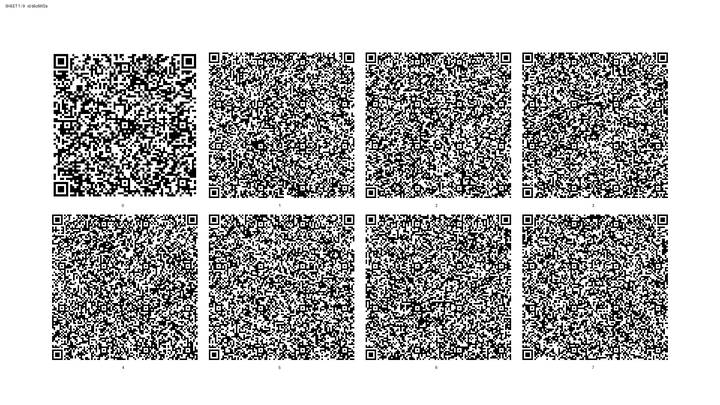

In [ ]:
from PIL import Image, ImageDraw


def draw_matrix(matrix, scale, quiet=agpack.QUIET_ZONE):
    n = len(matrix)
    side = (n + 2 * quiet) * scale
    img = Image.new("L", (side, side), 255)
    px = img.load()
    for y, row in enumerate(matrix):
        for x, on in enumerate(row):
            if on:
                x0, y0 = (x + quiet) * scale, (y + quiet) * scale
                for dy in range(scale):
                    for dx in range(scale):
                        px[x0 + dx, y0 + dy] = 0
    return img


def render_sheet(batch, layout, screen=(1920, 1080), label=""):
    scale = layout["px_per_module"]
    sheet = Image.new("L", screen, 255)
    d = ImageDraw.Draw(sheet)
    qr_px = layout["qr_px"]
    cols, rows = layout["cols"], layout["rows"]
    gap, top = 6, 34
    grid_w = cols * qr_px + (cols - 1) * gap
    grid_h = rows * (qr_px + 14) + (rows - 1) * gap
    ox = (screen[0] - grid_w) // 2
    oy = top + max(0, (screen[1] - top - grid_h) // 2)
    d.text((14, 10), label, fill=0)
    for i, (seq, text) in enumerate(batch):
        r, c = divmod(i, cols)
        img = draw_matrix(backend.matrix(text, "M"), scale)
        x = ox + c * (qr_px + gap)
        y = oy + r * (qr_px + 14 + gap)
        sheet.paste(img.resize((qr_px, qr_px), Image.NEAREST), (x, y))
        d.text((x + qr_px // 2 - 8, y + qr_px + 2), str(seq), fill=0)
    return sheet


per_sheet = layout["cols"] * layout["rows"]
sheets = [frames[i : i + per_sheet] for i in range(0, len(frames), per_sheet)]
print(
    f"{len(sheets)} sheet(s), {per_sheet} symbols each, "
    f"{layout['qr_px']}px symbols at {layout['px_per_module']} px/module"
)

import io as _io
from IPython.display import Image as IPyImage


def show(img, width=720, quality=70):
    """Display at a modest size as JPEG - keeps this notebook's own outputs small."""
    h = int(img.height * width / img.width)
    buf = _io.BytesIO()
    img.convert("RGB").resize((width, h), Image.LANCZOS).save(buf, "JPEG", quality=quality)
    return IPyImage(data=buf.getvalue(), format="jpeg")


sheet0 = render_sheet(sheets[0], layout, label=f"SHEET 1 / {len(sheets)}   id {transfer_id:08x}")
show(sheet0)

That's one screen. You'd photograph it, press `→`, photograph the next.

## 6. Photograph it (badly, on purpose)

Real phone photos are tilted, slightly blurred, glared and JPEG-compressed. If the
pipeline only worked on clean renders it would be worthless, so the demo degrades every
sheet before decoding:

9 simulated photo(s) in /tmp/agdemo-7qnov4qi/photos


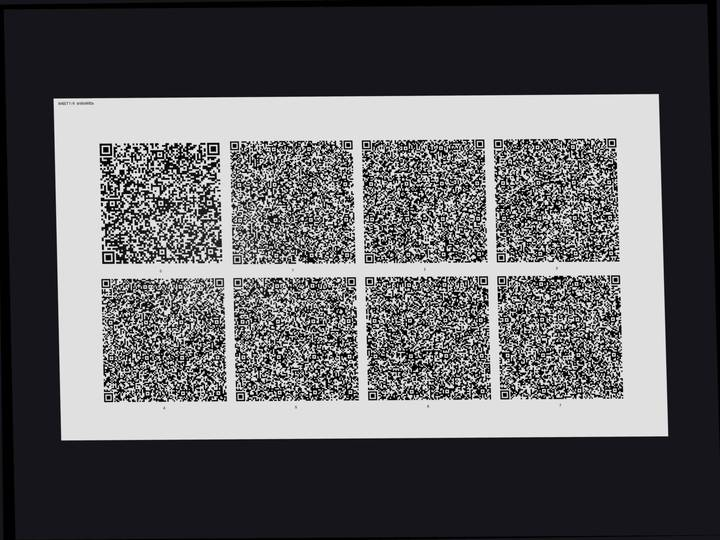

In [ ]:
import random
from PIL import ImageEnhance, ImageFilter


def perspective_coeffs(src, dst):
    m = []
    for (sx, sy), (dx, dy) in zip(src, dst):
        m.append([dx, dy, 1, 0, 0, 0, -sx * dx, -sx * dy])
        m.append([0, 0, 0, dx, dy, 1, -sy * dx, -sy * dy])
    B = [c for p in src for c in p]
    M = [m[i][:] + [B[i]] for i in range(8)]
    for col in range(8):
        piv = max(range(col, 8), key=lambda r: abs(M[r][col]))
        M[col], M[piv] = M[piv], M[col]
        pv = M[col][col]
        for j in range(col, 9):
            M[col][j] /= pv
        for r in range(8):
            if r != col and M[r][col]:
                f = M[r][col]
                for j in range(col, 9):
                    M[r][j] -= f * M[col][j]
    return [M[i][8] for i in range(8)]


def photograph(sheet, seed=0, sensor=(4032, 3024), fill=0.86, rot=1.4, tilt=0.02, blur=1.1, jpeg=72):
    """Imitate a handheld phone shot of a monitor."""
    rng = random.Random(seed)
    img = sheet.convert("RGB")
    h = int(sensor[1] * fill)
    w = int(img.width * h / img.height)
    if w > sensor[0] * fill:
        w = int(sensor[0] * fill)
        h = int(img.height * w / img.width)
    img = img.resize((w, h), Image.LANCZOS)

    # specular glare from a ceiling light
    g = Image.new("L", img.size, 0)
    gd = ImageDraw.Draw(g)
    cx, cy = rng.uniform(0.15, 0.85) * w, rng.uniform(0.1, 0.5) * h
    r = rng.uniform(0.18, 0.30) * h
    gd.ellipse([cx - r, cy - r * 0.6, cx + r, cy + r * 0.6], fill=70)
    g = g.filter(ImageFilter.GaussianBlur(r * 0.55))
    img = Image.composite(Image.new("RGB", img.size, (255, 255, 255)), img, g)

    canvas = Image.new("RGB", sensor, (26, 26, 30))
    canvas.paste(img, ((sensor[0] - w) // 2 + rng.randint(-40, 40), (sensor[1] - h) // 2 + rng.randint(-40, 40)))
    W, H = canvas.size
    src = [(0, 0), (W, 0), (W, H), (0, H)]
    dst = [
        (W * rng.uniform(0, tilt), H * rng.uniform(0, tilt)),
        (W * (1 - rng.uniform(0, tilt)), H * rng.uniform(0, tilt)),
        (W * (1 - rng.uniform(0, tilt)), H * (1 - rng.uniform(0, tilt))),
        (W * rng.uniform(0, tilt), H * (1 - rng.uniform(0, tilt))),
    ]
    canvas = canvas.transform((W, H), Image.PERSPECTIVE, perspective_coeffs(src, dst), Image.BICUBIC)
    canvas = canvas.rotate(rng.uniform(-rot, rot), resample=Image.BICUBIC, fillcolor=(26, 26, 30))
    canvas = canvas.filter(ImageFilter.GaussianBlur(blur))
    canvas = ImageEnhance.Brightness(canvas).enhance(rng.uniform(0.88, 1.06))
    return canvas, jpeg


PHOTOS = WORK / "photos"
PHOTOS.mkdir(exist_ok=True)
for i, batch in enumerate(sheets, 1):
    s = render_sheet(batch, layout, label=f"SHEET {i} / {len(sheets)}   id {transfer_id:08x}")
    shot, q = photograph(s, seed=i)
    shot.save(PHOTOS / f"IMG_{i:04d}.jpg", "JPEG", quality=q)

print(f"{len(sheets)} simulated photo(s) in {PHOTOS}")
show(Image.open(PHOTOS / "IMG_0001.jpg"))

Tilted, soft, washed out in one corner. This is roughly what you'd get holding a phone
at arm's length without trying very hard.

## 7. Decode and rebuild

`agunpack` scans the photos, drops any symbol failing its CRC, dedupes by sequence
number, checks the reassembled payload against the manifest SHA-256, then extracts —
verifying every file's own hash afterwards.

In [ ]:
REBUILT = WORK / "rebuilt"
r = run("agunpack.py", "--work", WORK / "agwork", "decode", PHOTOS, "--out", REBUILT, show=False)
print(clean(r.stdout))

scanning 9 image(s) with 2 worker(s)

  all 69 frames recovered on the first pass

69 new frame(s) this run; 69 cached in /tmp/agdemo-7qnov4qi/agwork
have 69 / 69 frames (frame 0 = header, 1-68 = payload)

reassembled 39,680 bytes
  expected sha256 b5c66f2ae7da3b80f05c9a497cfc0ea7c83e8f36734d26cc3a01f982487fc35b
  actual   sha256 b5c66f2ae7da3b80f05c9a497cfc0ea7c83e8f36734d26cc3a01f982487fc35b
  MATCH

extracted 22 file(s) to /tmp/agdemo-7qnov4qi/rebuilt
  per-file sha256: 21 ok, 0 bad

Done. Nothing outside --out and --work was touched.


## 8. Prove it's actually identical

`MATCH` is the tool's own claim. Verify it independently — hash every file on both
sides and compare, including the executable bit.

In [ ]:
import hashlib, filecmp


def tree_hashes(root, skip=()):
    out = {}
    for p in sorted(pathlib.Path(root).rglob("*")):
        if p.is_file() and p.name not in skip:
            rel = str(p.relative_to(root))
            out[rel] = (hashlib.sha256(p.read_bytes()).hexdigest(), oct(p.stat().st_mode & 0o777))
    return out


before = tree_hashes(SRC, skip={".env"})  # .env intentionally not sent
after = tree_hashes(REBUILT, skip={".agpack-manifest.json"})

print(f"{'file':<28}{'sha256 (source)':<20}{'match':<8}{'mode'}")
print("-" * 64)
shown = [k for k in before if not k.startswith("vendor/")] + [k for k in before if k.startswith("vendor/")][:4]
for rel in shown:
    h, mode = before[rel]
    h2, mode2 = after.get(rel, ("-", "-"))
    print(f"{rel:<28}{h[:16]:<20}{'yes' if h2 == h else 'NO':<8}" f"{mode}{'' if mode2 == mode else ' -> ' + mode2}")
print(f"... and {len(before) - len(shown)} more vendor/ files")

mismatched = [r for r in before if after.get(r) != before[r]]
print(f"\n{len(before)} files compared, {len(mismatched)} mismatched")
print("identical:", before == after)
print(".env transferred:", (REBUILT / ".env").exists(), "  <- correctly left behind")

file                        sha256 (source)     match   mode
----------------------------------------------------------------
docs/README.md              e9633bf1db7daebf    yes     0o644
pkg/__init__.py             af8c4016284e7fbd    yes     0o644
pkg/io_utils.py             7b8fc571d5da10b8    yes     0o644
pkg/solver.py               1c26dbdcb997ffd1    yes     0o644
pyproject.toml              c341e6da6325aaf5    yes     0o644
run.sh                      ff1b508dfea6f16a    yes     0o755
vendor/__future__.py        981d4c398849f9eb    yes     0o644
vendor/_aix_support.py      78790b6fd80cd62f    yes     0o644
vendor/_collections_abc.py  ec646ef7e27aae26    yes     0o644
vendor/_compat_pickle.py    12c8356a3d40bd0a    yes     0o644
... and 11 more vendor/ files

21 files compared, 0 mismatched
identical: True
.env transferred: False   <- correctly left behind


## 9. The part you'll actually rely on: partial captures

You will miss a sheet, or one will come out blurred. That case is designed for rather
than treated as an error. Here we decode only the first photo, in a fresh cache:

In [ ]:
PARTIAL = WORK / "partial"
PARTIAL.mkdir(exist_ok=True)
keep = sorted(PHOTOS.glob("*.jpg"))[:3]  # pretend the rest came out blurred
for p in keep:
    shutil.copy(p, PARTIAL)
print(f"decoding only {len(keep)} of {len(sheets)} photos\n")

r = run("agunpack.py", "--work", WORK / "agwork2", "decode", PARTIAL, show=False)
print(clean(r.stdout))

decoding only 3 of 9 photos



scanning 3 image(s) with 2 worker(s)

  every photo yielded the full 8 symbols

24 new frame(s) this run; 24 cached in /tmp/agdemo-7qnov4qi/agwork2
have 24 / 69 frames (frame 0 = header, 1-68 = payload)

MISSING 45 frame(s):
    frames 24-68           -> re-shoot sheets 4-9

Re-photograph those sheets and run decode again with the new photos.
Already-decoded frames are kept, so you only need the missing ones.


It names the **sheets** to re-shoot, not just frame numbers. Re-photograph those, point
`decode` at the new photos with the *same* `--work` directory, and it merges with what's
already cached — no repeated effort, nothing lost.

Feeding it the rest now completes the transfer:

In [ ]:
r = run("agunpack.py", "--work", WORK / "agwork2", "decode", PHOTOS, "--out", WORK / "rebuilt2", show=False)
print(clean(r.stdout))

scanning 9 image(s) with 2 worker(s)

  all 69 frames recovered on the first pass

45 new frame(s) this run; 69 cached in /tmp/agdemo-7qnov4qi/agwork2
have 69 / 69 frames (frame 0 = header, 1-68 = payload)

reassembled 39,680 bytes
  expected sha256 b5c66f2ae7da3b80f05c9a497cfc0ea7c83e8f36734d26cc3a01f982487fc35b
  actual   sha256 b5c66f2ae7da3b80f05c9a497cfc0ea7c83e8f36734d26cc3a01f982487fc35b
  MATCH

extracted 22 file(s) to /tmp/agdemo-7qnov4qi/rebuilt2
  per-file sha256: 21 ok, 0 bad

Done. Nothing outside --out and --work was touched.


## 10. Doing this for real

**On the offline machine.** Type `agmini.py` in by hand — that's what it's sized for.
If you can get `agpack.py` over somehow, calibrate first:

```bash
python3 agpack.py --calibrate --screen 1920x1080 --out ~/qr-cal
```

Photograph those sheets exactly as you plan to shoot the real ones, bring them here, and
run `python3 agunpack.py calibrate ~/photos/calib`. A level passes only if a photo
decodes **every** symbol on its sheet. Use the densest passing level, then step down one
for margin. Ten minutes here saves re-shooting forty sheets later.

**Set `--screen` to the real resolution.** Throughput scales hard with it: 1080p → 1440p
roughly halves the photo count, and 4K halves it again. If that machine can drive an
external monitor, use the biggest one you can find.

**Clear notebook outputs before packing.** Measured on `kretsinger/`: 45 notebooks are
7.3 MB as-is (821 photos) versus 380 KB with outputs cleared (22 photos) — **38× less to
photograph**, losing only rendered plots you'd regenerate anyway.

```bash
jupyter nbconvert --clear-output --inplace **/*.ipynb
```

**Skip the data.** The `.parquet` in `kretsinger/` is 253 MB — over a million photos.
Treat data as non-transferable and regenerate it on this side.

Rough budget for a repo 2–3× the size of `kretsinger/`, code only: **50–70 photos at
1080p, 30–40 at 1440p.**

## 11. Clean up

Everything above lives in one temp directory:

In [ ]:
print(WORK)
print("\nremove with:")
print(f"  import shutil; shutil.rmtree('{WORK}')")

/tmp/agdemo-7qnov4qi

remove with:
  import shutil; shutil.rmtree('/tmp/agdemo-7qnov4qi')
